# TrafficVolume Dataset — Data Preparation  ·  v3

**Project:** Crowd Network Intelligence — 4G Operator Benchmarking
**Dataset:** `TrafficVolume.csv` — 138,469 rows × 10 columns
**Coverage:** Riyadh, Saudi Arabia · 2–4 November 2019

---

## What changed from v2

The v2 investigation was thorough and its conclusion was right. Two things are new:

| # | Change | Why |
|---|---|---|
| **1** | **The odometer records are flagged, not deleted** (§C.7) | v2 removed the 14 cumulative-counter records outright. The dashboard now carries a *Suppress implausible traffic samples* toggle, and a toggle needs both states to exist. The rows stay in the table with `is_odometer = True`; Notebook 03 aggregates them into a raw column and a clean column side by side. |
| **2** | **H3 hex keys alongside the degree bins** (§D.2) | Degree bins remain primary and are what the RSRP join uses. H3 travels as a second key so a future dashboard can switch grid without reprocessing. |

Everything else — the scoping rule, the duplicate rule, the timestamp handling, the
90,000 MB empirical break point and the four hypothesis tests that justify it — is
carried over from v2 **unchanged**, because each was verified against the raw file and
each was correct.

### A note on the 90,000 MB floor

It is worth being explicit about why this number and not a rounder one. The extreme tail
splits into two populations with a clean gap between them:

- **Population 1** (≥ 90,000 MB): 14 records, one operator, one direction, coefficient of
  variation 0.014 — mechanically tight. Strictly increasing in time. A lifetime counter.
- **Population 2** (11,250–90,000 MB): 16 records, spread across operators, CV 0.63 —
  the ordinary shape of heavy usage.

A lower cut — 50,000 MB, say — reaches into Population 2 and destroys a genuine
55,354 MB Operator A record. The threshold is not a physical ceiling; it is the middle of
an observed gap, and the removal is justified by the monotonic signature verified in §C.4,
not by the number itself.

---
## Section 0 — Environment Setup

Imports, paths, constants, and the logging contract. No data operations.

In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# Standard library
# ─────────────────────────────────────────────────────────────────────────────
import gc
from pathlib import Path

# ─────────────────────────────────────────────────────────────────────────────
# Third-party
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from scipy.stats import spearmanr        # monotonicity test (§C.4)

try:
    import matplotlib.pyplot as plt      # inline validation plots only
    HAS_PLT = True
except ImportError:
    HAS_PLT = False
    print("NOTE: matplotlib not installed — validation plots will be skipped.")

try:
    import h3                            # secondary spatial key; degree bins are primary
    HAS_H3 = True
except ImportError:
    HAS_H3 = False
    print("NOTE: h3 not installed — the H3 columns will be skipped.")
    print("      Install with:  pip install h3     (degree bins work regardless)")

# `display` exists in Jupyter; this fallback keeps the notebook runnable as a plain script
try:
    display
except NameError:
    def display(x): print(x.to_string() if hasattr(x, "to_string") else x)

print(f"pandas : {pd.__version__}")
print(f"numpy  : {np.__version__}")
print(f"h3     : {'yes' if HAS_H3 else 'not installed'}")

pandas : 3.0.2
numpy  : 2.4.4
h3     : yes


In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# Paths — resolved relative to this notebook, so the project folder can move
# ─────────────────────────────────────────────────────────────────────────────
BASE_DIR     = Path.cwd().parent if Path.cwd().name.lower() == "code" else Path.cwd()
DATA_DIR     = BASE_DIR / "Data"

# ─────────────────────────────────────────────────────────────────────────────
# Raw inputs. Look in this project's Data folder first; fall back to the v3
# folder next door, so v4 works whether or not you copied the 334 MB RSRP.csv
# across. Nothing is written to v3 — it is read-only here.
# ─────────────────────────────────────────────────────────────────────────────
def find_raw(filename):
    for cand in (DATA_DIR / filename,
                 BASE_DIR.parent / "v3" / "Data" / filename):
        if cand.exists():
            return cand
    raise FileNotFoundError(
        f"{filename} not found in {DATA_DIR} or {BASE_DIR.parent / 'v3' / 'Data'}. "
        f"Copy the raw file into Data/ and re-run."
    )

TRAFFIC_PATH = None   # resolved after the output folders are created
# ─────────────────────────────────────────────────────────────────────────────
# Output folders — one job each, so the folder Tableau opens contains only files
# Tableau should load
#
#   interim/    regenerable working files (parquet). Notebook 03 reads them;
#               nothing else ever should. Safe to delete and re-run.
#   processed/  the nine flat files Tableau loads. Nothing else goes here.
#   reference/  the audit trail — cleaning logs, the alias map. Documented
#               evidence, never a data source.
# ─────────────────────────────────────────────────────────────────────────────
INTERIM_DIR = DATA_DIR / "interim"
OUT_DIR     = DATA_DIR / "processed"
REF_DIR     = DATA_DIR / "reference"
for _d in (INTERIM_DIR, OUT_DIR, REF_DIR):
    _d.mkdir(parents=True, exist_ok=True)

TRAFFIC_PATH = find_raw("TrafficVolume.csv")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ─────────────────────────────────────────────────────────────────────────────
# Temporal constants — identical to Notebook 01
#
# Both tables must cover the same span. If they did not, a shared date filter in
# the dashboard could empty one panel while another still showed data.
# ─────────────────────────────────────────────────────────────────────────────
LOCAL_TZ = "Asia/Riyadh"                          # UTC+03:00, Arabia Standard Time
DATE_MIN, DATE_MAX = "2019-11-02", "2019-11-04"   # the three complete days

# ─────────────────────────────────────────────────────────────────────────────
# Spatial constants — identical to Notebook 01 so the bin keys join exactly
# ─────────────────────────────────────────────────────────────────────────────
LAT_MIN, LAT_MAX = 24.40, 25.10
LON_MIN, LON_MAX = 46.30, 47.25

BIN_SIZES = [(0.005, "500m"), (0.01, "1km"), (0.02, "2km")]
H3_RES    = [7, 8]

# ─────────────────────────────────────────────────────────────────────────────
# Technology scope
#
# NOTE: unlike RSRP this is a COMPARABILITY choice, not a validity one. A 3G
# traffic reading is a perfectly valid measurement — it is simply constrained by
# a different air interface, so mixing it in would make the coverage-to-traffic
# relationship incomparable. The out-of-scope rows are counted before removal.
# ─────────────────────────────────────────────────────────────────────────────
SCOPE_GENERATION = "4G"
SCOPE_CONNECTION = "Mobile"
SCOPE_DATA_STATE = "Enabled"

# ─────────────────────────────────────────────────────────────────────────────
# Accumulator properties
# ─────────────────────────────────────────────────────────────────────────────
ACCUMULATOR_WINDOW_S = 900        # each record covers a 15-minute window

# ─────────────────────────────────────────────────────────────────────────────
# Odometer detection (§C)
#
# EMPIRICAL BREAK POINT, not a physical ceiling. See the header note. Records at
# or above this floor are FLAGGED in v3, never dropped — the dashboard toggle
# needs both states to exist.
# ─────────────────────────────────────────────────────────────────────────────
ODOMETER_FLOOR  = 90_000          # MB
CANDIDATE_FLOOR = 11_250          # MB — probe point for the population split only

print(f"Base dir       : {BASE_DIR}")
print(f"Source         : {TRAFFIC_PATH}")
print(f"Interim dir    : {INTERIM_DIR}")
print(f"Output dir     : {OUT_DIR}")
print(f"Reference      : {REF_DIR}")
print(f"Odometer floor : {ODOMETER_FLOOR:,} MB   (FLAG, not drop)")

Base dir       : /root/v5
Source         : /root/v3/Data/TrafficVolume.csv
Interim dir    : /root/v5/Data/interim
Output dir     : /root/v5/Data/processed
Reference      : /root/v5/Data/reference
Odometer floor : 90,000 MB   (FLAG, not drop)


In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# Cleaning audit trail
#
# Identical contract to Notebook 01, so the two logs concatenate. `kind` marks
# whether a step removed rows (DROP), rewrote values (FIX), or only annotated
# them (FLAG).
# ─────────────────────────────────────────────────────────────────────────────
cleaning_log = []


def log_step(step_id, rule, rows_before, rows_after, rationale, kind="DROP"):
    # Record a cleaning step and print a readable summary.
    removed = rows_before - rows_after
    pct     = (100 * removed / rows_before) if rows_before else 0.0

    cleaning_log.append({
        "step": step_id, "kind": kind, "rule": rule,
        "rows_before": rows_before, "rows_after": rows_after,
        "removed": removed, "pct_removed": round(pct, 3),
        "rationale": rationale,
    })

    print(f"[{step_id}] ({kind}) {rule}")
    print(f"    before : {rows_before:,}")
    print(f"    after  : {rows_after:,}")
    print(f"    removed: {removed:,}  ({pct:.3f}%)")


def show_log():
    return pd.DataFrame(cleaning_log)[
        ["step", "kind", "rule", "rows_before", "rows_after", "removed", "pct_removed"]
    ]

---
## Stage A — Scope Reduction

Same order as Notebook 01: the cheapest, highest-yield filters run first so every
subsequent scan works on a smaller frame.

### A.1 Load the raw dataset

Every column is read as `str`. Deferring type inference means pandas cannot silently
coerce a malformed timestamp into `NaT` or a sentinel into a float before we have
looked at it. `keep_default_na=False` stops the literal strings `"NA"` and `"null"`
from being read as missing values — in this dataset they are not.

In [4]:
traffic = pd.read_csv(
    TRAFFIC_PATH,
    dtype=str,
    keep_default_na=False,
    na_values=[""],          # only a genuinely empty field counts as null
)

ROWS_ORIGINAL = len(traffic)

print(f"Rows    : {ROWS_ORIGINAL:,}")
print(f"Columns : {len(traffic.columns)}")
print(f"\n{list(traffic.columns)}")
display(traffic.head(3))

Rows    : 138,469
Columns : 10

['Timestamp', 'LocationLatitude', 'LocationLongitude', 'RadioConnectionType', 'Country', 'RadioNetworkGeneration', 'RadioOperatorName', 'TrafficDirection', 'TrafficVolume', 'RadioMobileDataEnabled']


,Timestamp,LocationLatitude,LocationLongitude,RadioConnectionType,Country,RadioNetworkGeneration,RadioOperatorName,TrafficDirection,TrafficVolume,RadioMobileDataEnabled
0,2019-11-02 00:45:00.000 +0300,24.636574,46.710026,Mobile,Saudi Arabia,3G,Operator A,Downlink,14.95763,Enabled
1,2019-11-02 00:45:00.000 +0300,24.636124,46.711742,Mobile,Saudi Arabia,3G,Operator A,Uplink,0.304565,Enabled
2,2019-11-02 00:00:00.000 +0300,24.636728,46.710229999999996,Mobile,Saudi Arabia,3G,Operator A,Downlink,20.965813,Enabled


### A.2 Categorical profile and null map

Before filtering anything, look at what is actually in each categorical column. This is
also where the technology mix is recorded — the counts printed here are the justification
for the scoping decision in §A.4.

In [5]:
print("Null count per column")
nulls = traffic.isna().sum()
print(nulls[nulls > 0].to_string() if nulls.any() else "  none — zero nulls throughout")

for col in ["RadioNetworkGeneration", "RadioConnectionType", "RadioOperatorName",
            "TrafficDirection", "RadioMobileDataEnabled", "Country"]:
    print(f"\n{col}")
    print(traffic[col].value_counts().to_string())

Null count per column
  none — zero nulls throughout

RadioNetworkGeneration
RadioNetworkGeneration
4G         104208
3G          32707
2G           1533
WiFi           19
Unknown         2

RadioConnectionType
RadioConnectionType
Mobile    136425
WiFi        2044

RadioOperatorName
RadioOperatorName
Operator A    68211
Operator B    40312
Operator C    29946

TrafficDirection
TrafficDirection
Downlink    69262
Uplink      69207

RadioMobileDataEnabled
RadioMobileDataEnabled
Enabled     138434
Disabled        35

Country
Country
Saudi Arabia    138469


### A.3 Granularity check

The two datasets are **not** on the same grid, and the difference matters for the join in
Notebook 03.

RSRP is a point measurement: one reading, one instant, one coordinate. Traffic is an
*accumulator*: each record reports the bytes moved during a 15-minute window. That is why
traffic timestamps land only on `:00`, `:15`, `:30` and `:45`, and why there are two orders
of magnitude fewer distinct coordinates. Aggregating them onto a shared spatial bin is
therefore the only sound way to relate the two — a row-level join would be meaningless.

In [6]:
well_formed = traffic["Timestamp"].str.match(r"^\d{4}-\d{2}-\d{2} ")
_probe = pd.to_datetime(traffic.loc[well_formed, "Timestamp"], utc=True, format="mixed")

print(f"Distinct timestamps  : {_probe.nunique():>10,}   (RSRP: 259,189)")
print(f"Minute values        : {sorted(_probe.dt.minute.unique())}")
print(f"Second values        : {sorted(_probe.dt.second.unique())}")
print(f"Distinct coordinates : "
      f"{traffic.groupby(['LocationLatitude','LocationLongitude']).ngroups:>10,}   (RSRP: 1,224,883)")

del _probe
gc.collect()

Distinct timestamps  :        299   (RSRP: 259,189)
Minute values        : [np.int32(0), np.int32(15), np.int32(30), np.int32(45)]
Second values        : [np.int32(0)]
Distinct coordinates :     41,958   (RSRP: 1,224,883)


44

### A.4 Apply the technology scope

**This is a comparability decision, not a validity one.** The 3G and 2G rows removed here
carry genuine traffic measurements — nothing is wrong with them. They are excluded because
the study benchmarks 4G, and a byte moved over a 3G bearer is not comparable to a byte
moved over LTE.

The counts are captured first, so the mix is on the record even though the rows leave.

In [7]:
tv_tech_mix = (
    traffic.groupby(["RadioOperatorName", "RadioNetworkGeneration"], dropna=False)
    .size().rename("n_rows").reset_index()
)
tv_tech_mix["pct_of_operator"] = (
    100 * tv_tech_mix["n_rows"] / tv_tech_mix.groupby("RadioOperatorName")["n_rows"].transform("sum")
).round(2)

print("Traffic records by operator and generation, BEFORE scoping:")
display(tv_tech_mix)

Traffic records by operator and generation, BEFORE scoping:


,RadioOperatorName,RadioNetworkGeneration,n_rows,pct_of_operator
0,Operator A,2G,1125,1.65
1,Operator A,3G,17434,25.56
2,Operator A,4G,49652,72.79
3,Operator B,2G,240,0.60
4,Operator B,3G,9262,22.98
5,Operator B,4G,30796,76.39
6,Operator B,WiFi,14,0.03
7,Operator C,2G,168,0.56
8,Operator C,3G,6011,20.07
9,Operator C,4G,23760,79.34


In [8]:
rows_before = len(traffic)

scope_mask = (
    (traffic["RadioNetworkGeneration"] == SCOPE_GENERATION) &
    (traffic["RadioConnectionType"]    == SCOPE_CONNECTION) &
    (traffic["RadioMobileDataEnabled"] == SCOPE_DATA_STATE)
)

traffic = traffic[scope_mask].reset_index(drop=True)

log_step(
    step_id="3.2",
    rule=f"Retain {SCOPE_GENERATION} + {SCOPE_CONNECTION} + data {SCOPE_DATA_STATE}",
    rows_before=rows_before,
    rows_after=len(traffic),
    rationale="Comparability scoping, not validity. 3G/2G traffic is valid but "
              "constrained by a different air interface; mixing it would make the "
              "coverage-to-traffic relationship incomparable.",
)

[3.2] (DROP) Retain 4G + Mobile + data Enabled
    before : 138,469
    after  : 102,577
    removed: 35,892  (25.921%)


### A.5 Remove exact duplicates

A byte-identical row — all ten columns matching — is a collection-SDK retransmission, not
two separate measurements. Note this is a *stricter* test than the one used in Notebook 01
for handset aliases: here we require every field to match, so nothing ambiguous is touched.

In [9]:
rows_before = len(traffic)
traffic = traffic.drop_duplicates(keep="first").reset_index(drop=True)

log_step(
    step_id="5.1",
    rule="Drop exact full-row duplicates (all 10 columns identical)",
    rows_before=rows_before,
    rows_after=len(traffic),
    rationale="Byte-identical records are collection-SDK artifacts.",
)

assert traffic.duplicated().sum() == 0, "Exact duplicates remain"

[5.1] (DROP) Drop exact full-row duplicates (all 10 columns identical)
    before : 102,577
    after  : 102,549
    removed: 28  (0.027%)


---
## Stage B — Normalisation

Timestamps and coordinates. Nothing here is a judgement call: a record either parses into a
valid instant inside the study window and a valid point inside Riyadh, or it does not.

### B.1 Drop corrupted timestamps

A subset of timestamps have lost their date component entirely — the string starts with a
time, not a date. This is the signature of a spreadsheet reformatting the column somewhere
upstream.

These are **unrecoverable**. Three candidate days are in the file and nothing in the record
distinguishes them, so any assignment would be a coin flip introducing more error than it
resolves.

In [10]:
well_formed = traffic["Timestamp"].str.match(r"^\d{4}-\d{2}-\d{2} ")

n_bad = int((~well_formed).sum())
if n_bad:
    print(f"Corrupted timestamp samples ({n_bad:,} rows):")
    print(traffic.loc[~well_formed, "Timestamp"].unique()[:6])
else:
    print("No corrupted timestamps found.")

rows_before = len(traffic)
traffic = traffic[well_formed].reset_index(drop=True)

log_step(
    step_id="1.2",
    rule="Drop records with corrupted timestamps",
    rows_before=rows_before,
    rows_after=len(traffic),
    rationale="Date component stripped by spreadsheet reformatting. Unrecoverable — "
              "three candidate days, no basis for assignment. Imputation would "
              "introduce more error than it resolves.",
)

Corrupted timestamp samples (20 rows):
<ArrowStringArray>
['00:00.0', '45:00.0', '15:00.0']
Length: 3, dtype: str
[1.2] (DROP) Drop records with corrupted timestamps
    before : 102,549
    after  : 102,529
    removed: 20  (0.020%)


### B.2 Parse timestamps and convert to local time

Several records carry a **foreign UTC offset** — a device whose clock was set to another
timezone. Truncating the offset and reading the wall-clock text at face value would misplace
those records by whole hours, which lands them in the wrong bar of every hourly chart.

Parsing with `utc=True` honours each record's declared offset, and a single
`tz_convert` then puts every record on Riyadh local time. Note the order matters: parse in
UTC first, convert once at the end.

In [11]:
print("UTC offsets present:")
print(traffic["Timestamp"].str[-5:].value_counts().to_string())

traffic["Timestamp"] = pd.to_datetime(traffic["Timestamp"], utc=True,
                                      format="mixed", errors="coerce")

rows_before = len(traffic)
traffic = traffic[traffic["Timestamp"].notna()].reset_index(drop=True)
traffic["Timestamp"] = traffic["Timestamp"].dt.tz_convert(LOCAL_TZ)

log_step(
    step_id="1.3",
    rule="Parse honouring declared UTC offset; convert to Asia/Riyadh",
    rows_before=rows_before,
    rows_after=len(traffic),
    rationale="Foreign offsets originate from misconfigured device clocks. "
              "Truncating the offset would misplace records by whole hours.",
)

UTC offsets present:


Timestamp
+0300    101600
+0600       454
+0400       194
+0500       125
+0800        50
+0530        40
+0200        36
+0100        20
+1300        10
[1.3] (DROP) Parse honouring declared UTC offset; convert to Asia/Riyadh
    before : 102,529
    after  : 102,529
    removed: 0  (0.000%)


### B.3 Restrict to the three complete days

Converting to local time pushes a small number of records across midnight into 1 or 5
November. These are timezone-conversion residue, not observation days — presenting a handful
of records as a fourth day would make every daily comparison misleading.

In [12]:
print("Records per date after conversion:")
print(traffic["Timestamp"].dt.date.value_counts().sort_index().to_string())

rows_before = len(traffic)
date_mask = traffic["Timestamp"].dt.date.astype(str).between(DATE_MIN, DATE_MAX)
traffic = traffic[date_mask].reset_index(drop=True)

log_step(
    step_id="1.4",
    rule=f"Restrict to complete days {DATE_MIN} to {DATE_MAX}",
    rows_before=rows_before,
    rows_after=len(traffic),
    rationale="Boundary-day records are timezone-conversion artifacts. Retaining a "
              "few dozen records as a 'day' would distort daily comparisons.",
)

Records per date after conversion:
Timestamp
2019-11-01       32
2019-11-02    33886
2019-11-03    34546
2019-11-04    34065


[1.4] (DROP) Restrict to complete days 2019-11-02 to 2019-11-04
    before : 102,529
    after  : 102,497
    removed: 32  (0.031%)


### B.4 Coordinate validity

Expected to remove **zero rows**. This step exists as a corruption assertion — it guards
against nulls, exact zeros, and Null Island `(0, 0)` coordinates. If it ever starts removing
rows, something changed upstream and the run should be investigated before the output is
trusted.

In [13]:
traffic["LocationLatitude"]  = pd.to_numeric(traffic["LocationLatitude"],  errors="coerce")
traffic["LocationLongitude"] = pd.to_numeric(traffic["LocationLongitude"], errors="coerce")

rows_before = len(traffic)
geo_mask = (
    traffic["LocationLatitude"].between(LAT_MIN, LAT_MAX) &
    traffic["LocationLongitude"].between(LON_MIN, LON_MAX)
)
traffic = traffic[geo_mask].reset_index(drop=True)

log_step(
    step_id="2.1-2.2",
    rule="Retain coordinates within the Riyadh bounding box",
    rows_before=rows_before,
    rows_after=len(traffic),
    rationale="Guards against null, zero, and Null Island coordinates. Expected to "
              "remove zero rows — functions as a corruption assertion.",
)

[2.1-2.2] (DROP) Retain coordinates within the Riyadh bounding box
    before : 102,497
    after  : 102,497
    removed: 0  (0.000%)


---
## Stage C — The Extreme-Value Investigation

The traffic distribution has a mean roughly a hundred times its median. That alone tells us
nothing: heavy-tailed is the *normal* shape for mobile data usage, and trimming a tail
because it is inconvenient is how real signal gets destroyed.

So the extremes are treated as a question with four candidate answers, and each is tested
against the data rather than assumed:

| | Hypothesis | Test | §  |
|---|---|---|---|
| **A** | Unit error — KB stored as MB | Does dividing by 1024 or 1000 land in the normal range? Is the whole file affected? | C.2 |
| **B** | Cumulative counter — a lifetime total, not a window delta | Are the values strictly increasing in time? Are the *increments* ordinary? | C.4 |
| **C** | Tethering — one device sharing a connection for hours | Are the readings sustained at one location? | C.6 |
| **D** | Aggregation artifact — a busy cell reported as one row | Is background traffic at those coordinates elevated? | C.6 |

Only **B** survives. That is what licenses the flag — not the size of the numbers.

### C.1 Distribution profile

In [14]:
traffic["TrafficVolume"] = pd.to_numeric(traffic["TrafficVolume"], errors="coerce")
tv = traffic["TrafficVolume"]

print("Traffic volume distribution (MB)")
print("─" * 56)
print(f"  min          : {tv.min():>12,.5f}")
print(f"  p25          : {tv.quantile(.25):>12,.3f}")
print(f"  MEDIAN       : {tv.quantile(.50):>12,.3f}")
print(f"  p75          : {tv.quantile(.75):>12,.3f}")
print(f"  p90          : {tv.quantile(.90):>12,.2f}")
print(f"  p99          : {tv.quantile(.99):>12,.2f}")
print(f"  p99.9        : {tv.quantile(.999):>12,.2f}")
print(f"  MEAN         : {tv.mean():>12,.2f}   <-- {tv.mean()/tv.median():.0f}x the median")
print(f"  max          : {tv.max():>12,.0f}")
print(f"\n  zero/negative: {(tv <= 0).sum()}    nulls: {tv.isna().sum()}")

Traffic volume distribution (MB)
────────────────────────────────────────────────────────
  min          :      0.00106
  p25          :        0.189
  MEDIAN       :        0.742
  p75          :        3.562
  p90          :        22.50
  p99          :       129.36
  p99.9        :     2,483.79
  MEAN         :        30.01   <-- 40x the median
  max          :      104,022

  zero/negative: 0    nulls: 0


### C.2 Test A — unit error

If a subset of rows had bytes or kilobytes mislabelled as megabytes, dividing by 1024 or
1000 would drop them neatly into the normal range, and the fault would be systematic — a
whole export, a whole operator, a whole day.

In [15]:
ext = traffic[traffic["TrafficVolume"] > CANDIDATE_FLOOR]

print("TEST A — unit error (KB mislabelled as MB)")
print("─" * 60)
print(f"Normal p99: {tv.quantile(.99):,.1f} MB\n")
print(f"Extreme values ÷1024 : {(ext['TrafficVolume']/1024).round(1).head(6).tolist()}")
print(f"Extreme values ÷1000 : {(ext['TrafficVolume']/1000).round(1).head(6).tolist()}")
print(f"\nAffected records: {len(ext)} of {len(traffic):,} "
      f"({100*len(ext)/len(traffic):.3f}%) — confined to a handful")
print("\nVERDICT: a genuine unit error would affect the whole file, not a few")
print("records from one operator. Hypothesis A REJECTED.")

TEST A — unit error (KB mislabelled as MB)
────────────────────────────────────────────────────────────
Normal p99: 129.4 MB

Extreme values ÷1024 : [16.8, 97.1, 98.9, 12.7, 12.5, 14.0]
Extreme values ÷1000 : [17.2, 99.4, 101.3, 13.0, 12.8, 14.3]

Affected records: 30 of 102,497 (0.029%) — confined to a handful

VERDICT: a genuine unit error would affect the whole file, not a few
records from one operator. Hypothesis A REJECTED.


### C.3 Rank-ordered gap detection

Rather than pick a threshold and defend it afterwards, sort the top values and look for a
break. A mechanical artifact and ordinary heavy usage are different *populations*, and
populations separate.

The coefficient of variation is the tell: a lifetime counter sampled a few times produces
values that sit almost on top of each other (CV near zero); real heavy users scatter.

In [16]:
top    = tv.nlargest(60).values
ratios = top[:-1] / top[1:]
jumps  = np.where(ratios > 1.5)[0]

print("Top 20 values:")
print(np.round(top[:20], 0).tolist())
print(f"\nRanks with a >1.5x drop to the next value: {jumps.tolist()}")
for j in jumps:
    print(f"  rank {j+1:>2}: {top[j]:>10,.0f} -> {top[j+1]:>10,.0f}   ({ratios[j]:.2f}x)")

# Characterise the two candidate populations
pop1 = tv[tv >= ODOMETER_FLOOR]
pop2 = tv[(tv > CANDIDATE_FLOOR) & (tv < ODOMETER_FLOOR)]

print(f"\n{'':22}{'Population 1':>16}{'Population 2':>16}")
print("─" * 54)
print(f"{'records':22}{len(pop1):>16,}{len(pop2):>16,}")
print(f"{'min (MB)':22}{pop1.min():>16,.0f}{pop2.min():>16,.0f}")
print(f"{'max (MB)':22}{pop1.max():>16,.0f}{pop2.max():>16,.0f}")
print(f"{'coeff. of variation':22}{pop1.std()/pop1.mean():>16.4f}{pop2.std()/pop2.mean():>16.4f}")
print("\nTight clustering (low CV) => mechanical artifact")
print("Wide spread (high CV)     => ordinary heavy usage")
print(f"\nPopulation 2 holds {pop2.sum()/1024:,.1f} GB of genuine traffic. A lower cut")
print("would delete it. This is why the floor sits in the gap and not below it.")

Top 20 values:
[104022.0, 103867.0, 103826.0, 103740.0, 103308.0, 103295.0, 103291.0, 102407.0, 102404.0, 102325.0, 101378.0, 101282.0, 100592.0, 99448.0, 55354.0, 17161.0, 16907.0, 14891.0, 14430.0, 14321.0]

Ranks with a >1.5x drop to the next value: [13, 14]
  rank 14:     99,448 ->     55,354   (1.80x)
  rank 15:     55,354 ->     17,161   (3.23x)

                          Population 1    Population 2
──────────────────────────────────────────────────────
records                             14              16
min (MB)                        99,448          12,567
max (MB)                       104,022          55,354
coeff. of variation             0.0136          0.6278

Tight clustering (low CV) => mechanical artifact
Wide spread (high CV)     => ordinary heavy usage

Population 2 holds 259.5 GB of genuine traffic. A lower cut
would delete it. This is why the floor sits in the gap and not below it.


### C.4 Test B — cumulative counter

The decisive test. If these are readings of a lifetime odometer rather than window deltas,
then:

1. the values must be **strictly increasing in time** (Spearman ρ ≈ 1.0), and
2. the **differences between consecutive readings** must look like ordinary usage.

Point 2 is what separates this from a coincidence. A counter that reads 90 GB, then 92 GB,
then 95 GB is not describing 90 GB of traffic in fifteen minutes — it is describing a couple
of gigabytes, on a device that happens to have moved 90 GB since it was last reset.

In [17]:
odometer = traffic[traffic["TrafficVolume"] >= ODOMETER_FLOOR].sort_values("Timestamp")

rho, pval = spearmanr(odometer["Timestamp"].astype("int64"), odometer["TrafficVolume"])
cv        = odometer["TrafficVolume"].std() / odometer["TrafficVolume"].mean()
rise      = odometer["TrafficVolume"].max() - odometer["TrafficVolume"].min()
hours     = (odometer["Timestamp"].max() - odometer["Timestamp"].min()).total_seconds() / 3600

print("TEST B — cumulative counter")
print("─" * 60)
print(f"Records                  : {len(odometer)}")
print(f"Spearman rho vs time     : {rho:.4f}   (p = {pval:.2e})")
print(f"Strictly increasing      : {(odometer['TrafficVolume'].diff().dropna() > 0).all()}")
print(f"Coefficient of variation : {cv:.4f}")
print(f"Operators                : {odometer['RadioOperatorName'].value_counts().to_dict()}")
print(f"Directions               : {odometer['TrafficDirection'].value_counts().to_dict()}")

print(f"\nTotal rise  : {rise:,.0f} MB over {hours:.1f} hours")
print(f"Implied rate: {rise/hours:.1f} MB/hour")
print(f"Compare     : dataset median = {tv.median():.2f} MB per 15-min window "
      f"(= {tv.median()*4:.2f} MB/hour)")

print("\nInter-reading increments:")
d = odometer["TrafficVolume"].diff().dropna()
h = odometer["Timestamp"].diff().dropna().dt.total_seconds() / 3600
for dv, hh in zip(d.round(1), h.round(2)):
    print(f"    +{dv:>8,} MB over {hh:>6} h  =  {dv/hh:>6.1f} MB/h")

TEST B — cumulative counter
────────────────────────────────────────────────────────────
Records                  : 14
Spearman rho vs time     : 1.0000   (p = 0.00e+00)
Strictly increasing      : True
Coefficient of variation : 0.0136
Operators                : {'Operator B': 14}
Directions               : {'Downlink': 14}

Total rise  : 4,574 MB over 69.8 hours
Implied rate: 65.6 MB/hour
Compare     : dataset median = 0.74 MB per 15-min window (= 2.97 MB/hour)

Inter-reading increments:
    + 1,144.1 MB over   17.5 h  =    65.4 MB/h
    +   690.0 MB over    4.5 h  =   153.3 MB/h
    +    96.0 MB over   1.25 h  =    76.8 MB/h
    +   947.0 MB over   18.5 h  =    51.2 MB/h
    +    79.0 MB over    2.5 h  =    31.6 MB/h
    +     3.0 MB over   0.25 h  =    12.0 MB/h
    +   884.0 MB over   17.0 h  =    52.0 MB/h
    +     4.0 MB over   1.25 h  =     3.2 MB/h
    +    13.0 MB over    0.5 h  =    26.0 MB/h
    +   432.0 MB over   4.25 h  =   101.6 MB/h
    +    86.0 MB over    0.5 h  =   

### C.5 Visual confirmation

Left: the reported values against time — a straight climb, never once falling.
Right: the implied rate between consecutive readings — entirely ordinary.

The contrast between the two panels *is* the finding. A large number that rises
monotonically while its increments stay ordinary is a counter, not a measurement.

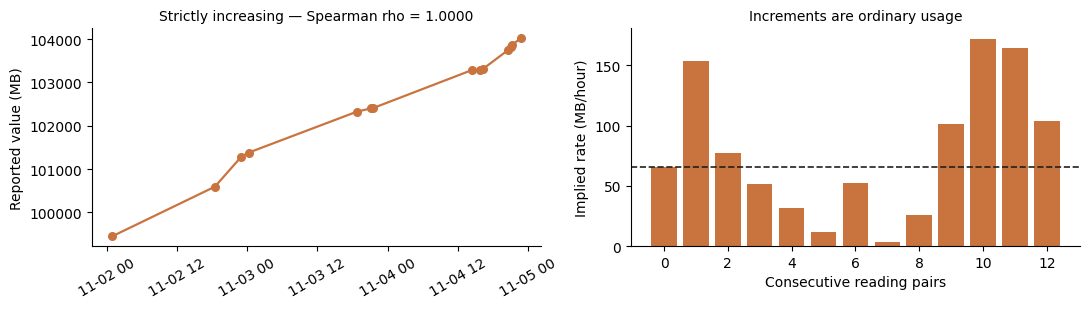

In [18]:
if HAS_PLT:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))

    ax1.plot(odometer["Timestamp"], odometer["TrafficVolume"], "o-",
             color="#c9743f", ms=5.5, lw=1.6)
    ax1.set_ylabel("Reported value (MB)")
    ax1.set_title(f"Strictly increasing — Spearman rho = {rho:.4f}", fontsize=10)
    ax1.tick_params(axis="x", rotation=30)

    ax2.bar(range(len(d)), (d / h).values, color="#c9743f")
    ax2.axhline(rise / hours, color="#23201d", ls="--", lw=1.2)
    ax2.set_ylabel("Implied rate (MB/hour)")
    ax2.set_xlabel("Consecutive reading pairs")
    ax2.set_title("Increments are ordinary usage", fontsize=10)

    for ax in (ax1, ax2):
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)

    plt.tight_layout(); plt.show()
else:
    print("matplotlib unavailable — see the numeric output in the previous cell.")

### C.6 Tests C and D — the remaining alternatives

**C — tethering.** A phone sharing its connection with several laptops for an evening could
plausibly move this much data. But it would do so *sitting still*: repeated windows at one
coordinate.

**D — aggregation artifact.** If a busy cell were being reported as a single row, the
ordinary traffic at those same coordinates would also be elevated.

In [19]:
print("TEST C — tethering session?")
print("─" * 60)
runs = (
    odometer.sort_values(["LocationLatitude", "LocationLongitude", "Timestamp"])
    .groupby(["LocationLatitude", "LocationLongitude"])
    .agg(n_windows=("Timestamp", "size"),
         span_min=("Timestamp", lambda x: (x.max() - x.min()).total_seconds() / 60))
)
print(f"Distinct locations       : {len(runs)}")
print(f"Locations with >1 window : {(runs['n_windows'] > 1).sum()}")
print(f"Spatial spread           : "
      f"{(odometer['LocationLatitude'].max()-odometer['LocationLatitude'].min())*111:.1f} km N-S x "
      f"{(odometer['LocationLongitude'].max()-odometer['LocationLongitude'].min())*101:.1f} km E-W")
print("\nVERDICT: readings are dispersed across the city, not sustained at one")
print("location. Hypothesis C REJECTED.")

print("\n\nTEST D — aggregation artifact?")
print("─" * 60)
odo_coords = set(zip(odometer["LocationLatitude"], odometer["LocationLongitude"]))
at_odo = traffic[
    traffic.set_index(["LocationLatitude", "LocationLongitude"]).index.isin(odo_coords)
]
normal_there = at_odo[at_odo["TrafficVolume"] < ODOMETER_FLOOR]["TrafficVolume"]

print(f"Median ordinary traffic at those coordinates : {normal_there.median():.2f} MB")
print(f"Median ordinary traffic everywhere           : {tv.median():.2f} MB")
print("\nVERDICT: no elevated background density. Hypothesis D REJECTED.")

TEST C — tethering session?
────────────────────────────────────────────────────────────
Distinct locations       : 12
Locations with >1 window : 2
Spatial spread           : 6.1 km N-S x 17.3 km E-W

VERDICT: readings are dispersed across the city, not sustained at one
location. Hypothesis C REJECTED.


TEST D — aggregation artifact?
────────────────────────────────────────────────────────────
Median ordinary traffic at those coordinates : 0.76 MB
Median ordinary traffic everywhere           : 0.74 MB

VERDICT: no elevated background density. Hypothesis D REJECTED.


### C.7 ⭐ Flag the odometer records — do not delete them

**This is the one place v3 departs from v2.**

v2 removed these 14 rows and moved on. That was defensible: they are not measurements, and
including them inflates Operator B's downlink total by 4.1× — 1,854 GB reported against
452 GB actually moved.

But the dashboard has a **Suppress implausible traffic samples** toggle, and a toggle needs
both states to exist. If the rows are gone from the table, the "off" position of the toggle
has nothing to show, and — more importantly — a reviewer can no longer check the claim. So
the rows stay, carrying `is_odometer = True`, and Notebook 03 aggregates them into a raw
column and a clean column side by side.

**The guard rails still fire.** If a future extract lacks the monotonic signature, the
assertions below stop the notebook rather than let it flag records on a threshold that was
only ever a proxy for evidence.

In [20]:
# Guard rails: refuse to flag unless the signature is actually present.
assert rho > 0.99, "Monotonic signature absent — do NOT flag; re-run the tests"
assert cv  < 0.05, "Values not tightly clustered — not a counter artifact"

rows_before = len(traffic)
traffic["is_odometer"] = traffic["TrafficVolume"] >= ODOMETER_FLOOR

log_step(
    step_id="4.2",
    rule=f"FLAG {int(traffic['is_odometer'].sum())} cumulative-odometer records "
         f"(>= {ODOMETER_FLOOR:,} MB) — no rows removed",
    rows_before=rows_before,
    rows_after=len(traffic),
    kind="FLAG",
    rationale=f"Strictly monotonic in time (Spearman rho={rho:.4f}), CV={cv:.4f}, "
              f"single operator, single direction. Reported value is a lifetime running "
              f"total, not a window delta; increments average {rise/hours:.0f} MB/h — "
              f"ordinary usage. Flagged rather than deleted so the dashboard toggle can "
              f"show both states and a reviewer can verify the claim.",
)

print(f"\nRows flagged : {int(traffic['is_odometer'].sum())}")
print(f"Volume flagged: {traffic.loc[traffic['is_odometer'], 'TrafficVolume'].sum()/1024:,.1f} GB")

[4.2] (FLAG) FLAG 14 cumulative-odometer records (>= 90,000 MB) — no rows removed
    before : 102,497
    after  : 102,497
    removed: 0  (0.000%)

Rows flagged : 14
Volume flagged: 1,401.5 GB


### C.8 Impact of the correction

What the toggle actually changes. Note that the *median* is untouched — 14 rows cannot move
it — while Operator A's uplink total falls by roughly three quarters. That is the signature
of a total driven by a handful of records rather than by its distribution.

In [21]:
grp = ["RadioOperatorName", "TrafficDirection"]

impact_raw = (traffic.groupby(grp, observed=True)["TrafficVolume"]
              .agg(["count", "sum", "median"]).round(2))
impact_cln = (traffic[~traffic["is_odometer"]].groupby(grp, observed=True)["TrafficVolume"]
              .agg(["count", "sum", "median"]).round(2))

comparison = pd.DataFrame({
    "sum_raw":       impact_raw["sum"],
    "sum_clean":     impact_cln["sum"],
    "pct_change":    (100 * (impact_cln["sum"] - impact_raw["sum"])
                      / impact_raw["sum"]).round(1),
    "median_raw":    impact_raw["median"],
    "median_clean":  impact_cln["median"],
})

print("IMPACT OF THE CORRECTION  (raw = toggle off, clean = toggle on)")
display(comparison)

worst = comparison["pct_change"].idxmin()
print(f"\nLargest effect: {worst[0]} {worst[1]} — "
      f"{comparison.loc[worst, 'sum_raw']/1024:,.1f} GB falls to "
      f"{comparison.loc[worst, 'sum_clean']/1024:,.1f} GB "
      f"({comparison.loc[worst, 'pct_change']:.1f}%).")
print("Every other operator/direction pair is unchanged — the artifact is confined.")

IMPACT OF THE CORRECTION  (raw = toggle off, clean = toggle on)


sum_raw  sum_clean  pct_change  median_raw  median_clean
RadioOperatorName TrafficDirection                                                             
Operator A        Downlink           646895.78  646895.78         0.0        1.77          1.77
                  Uplink              57248.60   57248.60         0.0        0.35          0.35
Operator B        Downlink          1898344.27  463159.38       -75.6        2.64          2.62
                  Uplink             104642.22  104642.22         0.0        0.47          0.47
Operator C        Downlink           329176.26  329176.26         0.0        2.33          2.33
                  Uplink              39969.79   39969.79         0.0        0.46          0.46


Largest effect: Operator B Downlink — 1,853.9 GB falls to 452.3 GB (-75.6%).
Every other operator/direction pair is unchanged — the artifact is confined.


---
## Stage D — Feature Derivation

The row set is final. Everything below is derived, and every derived field is deterministic
from the columns already present.

### D.1 Temporal features

`hour_of_week` gives a single 0–167 ordinal for the weekly heatmap, so a chart does not have
to sort day names — which sort alphabetically by default, putting Friday before Monday.

In [22]:
traffic["date"]         = traffic["Timestamp"].dt.date
traffic["hour"]         = traffic["Timestamp"].dt.hour
traffic["day_of_week"]  = traffic["Timestamp"].dt.day_name()
traffic["hour_of_week"] = traffic["Timestamp"].dt.dayofweek * 24 + traffic["hour"]

print("Total volume by hour (MB), excluding flagged records:")
print(traffic[~traffic["is_odometer"]].groupby("hour")["TrafficVolume"]
      .sum().round(0).to_string())

Total volume by hour (MB), excluding flagged records:


hour
0      55395.0
1      41476.0
2      31589.0
3      31099.0
4      12469.0
5      10635.0
6      19908.0
7      44941.0
8      73675.0
9      40389.0
10     39665.0
11     78447.0
12     97204.0
13     88168.0
14     92115.0
15     90228.0
16    101330.0
17     85825.0
18     93374.0
19    156711.0
20    111799.0
21     89125.0
22     93213.0
23     62311.0


### D.2 Spatial bins — degree grid (primary) and H3 (secondary)

**Construction is identical to Notebook 01.** The join in Notebook 03 depends on these keys
matching byte for byte, so both notebooks build them from the same constants with the same
rounding.

*Degree bins* are the primary grid: a plain `round(lat/size)_round(lon/size)` key that any
tool can reproduce without a library. At Riyadh's latitude one degree of longitude is about
101 km against 111 km for latitude, so the cells are ~10% wider than they are tall. For
counting samples inside a cell that does not matter.

*H3* cells are true hexagons of equal area, which does matter for neighbour-based analysis —
smoothing, contouring, finding adjacent weak cells. They ride along as a second key so that
work never requires reprocessing.

In [23]:
for deg, label in BIN_SIZES:
    traffic[f"bin_{label}"] = (
        (traffic["LocationLatitude"]  / deg).round().astype(int).astype(str) + "_" +
        (traffic["LocationLongitude"] / deg).round().astype(int).astype(str)
    )
    print(f"{label:>6} bins: {traffic[f'bin_{label}'].nunique():,} distinct cells")

  500m bins: 3,841 distinct cells


   1km bins: 1,443 distinct cells
   2km bins: 498 distinct cells


In [24]:
if HAS_H3:
    lats = traffic["LocationLatitude"].to_numpy()
    lons = traffic["LocationLongitude"].to_numpy()

    # Unique coordinates only — H3 conversion is the expensive step and the traffic
    # table repeats coordinates heavily.
    uniq = pd.DataFrame({"lat": lats, "lon": lons}).drop_duplicates()
    print(f"Unique coordinates to convert: {len(uniq):,}")

    for res in H3_RES:
        lookup = {
            (la, lo): h3.latlng_to_cell(la, lo, res)
            for la, lo in zip(uniq["lat"], uniq["lon"])
        }
        traffic[f"h3_r{res}"] = [lookup[(la, lo)] for la, lo in zip(lats, lons)]
        edge_km = h3.average_hexagon_edge_length(res, unit="km")
        print(f"h3_r{res}: {traffic[f'h3_r{res}'].nunique():,} cells   (edge {edge_km:.2f} km)")

    del uniq, lookup
    gc.collect()
else:
    print("h3 not installed — skipping H3 keys. Degree bins are unaffected.")

Unique coordinates to convert: 32,706


h3_r7: 462 cells   (edge 1.41 km)


h3_r8: 2,003 cells   (edge 0.53 km)


### D.3 Log-transformed volume

The distribution spans five orders of magnitude and is approximately log-normal. `tv_log10`
is the right scale for modelling and for any visualisation of the distribution itself —
though **totals must always be summed on the raw scale**, never on the log.

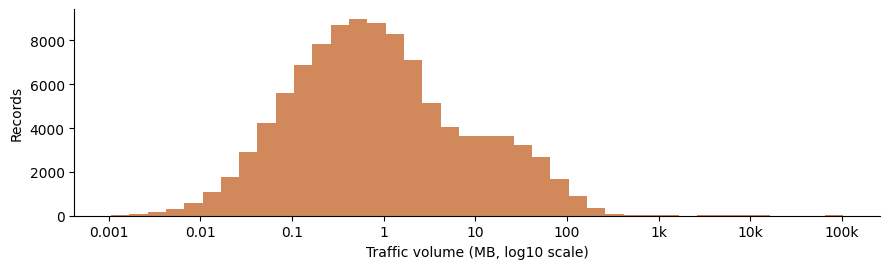

Non-positive volumes (excluded from the log): 0


In [25]:
traffic["tv_log10"] = np.log10(traffic["TrafficVolume"].where(traffic["TrafficVolume"] > 0))

if HAS_PLT:
    fig, ax = plt.subplots(figsize=(9, 2.8))
    ax.hist(traffic["tv_log10"].dropna(), bins=40, color="#c9743f", alpha=.85)
    ax.set_xlabel("Traffic volume (MB, log10 scale)")
    ax.set_ylabel("Records")
    ax.set_xticks([-3, -2, -1, 0, 1, 2, 3, 4, 5])
    ax.set_xticklabels(["0.001", "0.01", "0.1", "1", "10", "100", "1k", "10k", "100k"])
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout(); plt.show()

print(f"Non-positive volumes (excluded from the log): {int((traffic['TrafficVolume'] <= 0).sum())}")

### D.4 Type optimisation

In [26]:
for col in ["RadioOperatorName", "RadioNetworkGeneration", "RadioConnectionType",
            "TrafficDirection", "day_of_week"]:
    traffic[col] = traffic[col].astype("category")

print(f"Memory after optimisation: {traffic.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

Memory after optimisation: 22.1 MB


---
## Reconciliation

The sum of logged removals must equal the total row reduction. If it does not, rows left the
frame outside the logged path — a merge that dropped keys, an accidental `dropna`, a bad
index. Better to fail here than to discover it in Notebook 03.

In [27]:
log_df = show_log()
display(log_df)

final = len(traffic)
print(f"\nOriginal rows : {ROWS_ORIGINAL:,}")
print(f"Final rows    : {final:,}")
print(f"Removed       : {ROWS_ORIGINAL - final:,}  "
      f"({100*(ROWS_ORIGINAL-final)/ROWS_ORIGINAL:.2f}%)")
print(f"Flagged       : {int(traffic['is_odometer'].sum())} (retained, not removed)")

assert log_df["removed"].sum() == ROWS_ORIGINAL - final, \
    "Logged removals do not reconcile with the total row reduction"
print("\nReconciliation passed — every removed row is accounted for in the log.")

,step,kind,rule,rows_before,rows_after,removed,pct_removed
0,3.2,DROP,Retain 4G + Mobile + data Enabled,138469,102577,35892,25.921
1,5.1,DROP,Drop exact full-row duplicates (all 10 columns...,102577,102549,28,0.027
2,1.2,DROP,Drop records with corrupted timestamps,102549,102529,20,0.020
3,1.3,DROP,Parse honouring declared UTC offset; convert t...,102529,102529,0,0.000
4,1.4,DROP,Restrict to complete days 2019-11-02 to 2019-1...,102529,102497,32,0.031
5,2.1-2.2,DROP,Retain coordinates within the Riyadh bounding box,102497,102497,0,0.000
6,4.2,FLAG,"FLAG 14 cumulative-odometer records (>= 90,000...",102497,102497,0,0.000



Original rows : 138,469
Final rows    : 102,497
Removed       : 35,972  (25.98%)
Flagged       : 14 (retained, not removed)

Reconciliation passed — every removed row is accounted for in the log.


---
## Persist

In [28]:
# The clean table is an INTERMEDIATE — Notebook 03 reads it, Tableau does not.
try:
    INTERMEDIATE = INTERIM_DIR / "traffic_clean.parquet"
    traffic.to_parquet(INTERMEDIATE, index=False)
except (ImportError, ValueError) as exc:
    print(f"NOTE: parquet unavailable ({type(exc).__name__}) — writing pickle instead.")
    INTERMEDIATE = INTERIM_DIR / "traffic_clean.pkl"
    traffic.to_pickle(INTERMEDIATE)

log_df.to_csv(REF_DIR / "traffic_cleaning_log.csv", index=False)
tv_tech_mix.to_csv(REF_DIR / "traffic_tech_mix.csv", index=False)

size_mb = INTERMEDIATE.stat().st_size / 1024**2
print(f"interim/   {INTERMEDIATE.name:<24} {len(traffic):>8,} rows  {size_mb:>5.1f} MB  [for Notebook 03]")
print(f"reference/ traffic_cleaning_log.csv   {len(log_df):>8,} steps              [audit trail]")
print(f"reference/ traffic_tech_mix.csv       {len(tv_tech_mix):>8,} rows               [audit trail]")

interim/   traffic_clean.parquet     102,497 rows    3.5 MB  [for Notebook 03]
reference/ traffic_cleaning_log.csv          7 steps              [audit trail]
reference/ traffic_tech_mix.csv             12 rows               [audit trail]


---
## Summary

`interim/traffic_clean.parquet` — scoped to 4G mobile, deduplicated, timezone-corrected, bounded to
the three complete days, with degree bins, H3 keys, temporal features, and the odometer
flag.

### Carried forward into Notebook 03

- **`is_odometer` is a flag, not a filter.** Every traffic export must carry `tv_sum`
  (flagged rows excluded) *and* `tv_sum_raw` (all rows) so the suppression toggle works.
- **Bin keys are constructed identically to Notebook 01.** The spatial join depends on it.
- **Totals sum on the raw MB scale**, never on `tv_log10`.